# ITEC0424-002 Computer Vision - Individual Assignment01 (Image Filtering)

#Student No: 2024017879
#Name: Likith Nagamangala Ashok

In [3]:
import os, itertools
import numpy as np, cv2, matplotlib.pyplot as plt
def find(name):
    for p in (os.path.join("data", name), name):
        if os.path.exists(p): return p
    raise FileNotFoundError(f"{name} not found - upload it to data/")
print("OpenCV", cv2.__version__, "| numpy", np.__version__)

OpenCV 5.0.0 | numpy 2.1.3


# #1 Thresholding

Three rules (strict inequalities, as in the assignment):
- **Binary**: 255 if `I > T` else 0
- **Inverse binary**: 255 if `I < T` else 0
- **Window**: 255 if `T1 < I < T2` else 0

intensity value -> pixel count: {33: 392, 75: 687, 128: 45296, 129: 2864, 130: 2916, 131: 2020, 132: 1992, 133: 7845, 180: 801, 222: 723}
Digit intensities: 1=33, 4=75, background=128, 3=130 (on a disc of 129..133), 5=180, 2=222


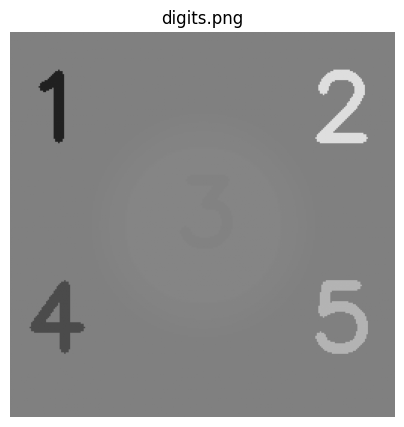

In [4]:
img = cv2.imread(find("digits.png"), cv2.IMREAD_GRAYSCALE)
def binary(im, T):      return np.where(im > T, 255, 0).astype(np.uint8)
def binary_inv(im, T):  return np.where(im < T, 255, 0).astype(np.uint8)
def window(im, T1, T2): return np.where((im > T1) & (im < T2), 255, 0).astype(np.uint8)
vals, cnt = np.unique(img, return_counts=True)
print("intensity value -> pixel count:", dict(zip(vals.tolist(), cnt.tolist())))
print("Digit intensities: 1=33, 4=75, background=128, 3=130 (on a disc of 129..133), 5=180, 2=222")
plt.figure(figsize=(5,5)); plt.imshow(img, cmap="gray", vmin=0, vmax=255); plt.title("digits.png"); plt.axis("off"); plt.show()

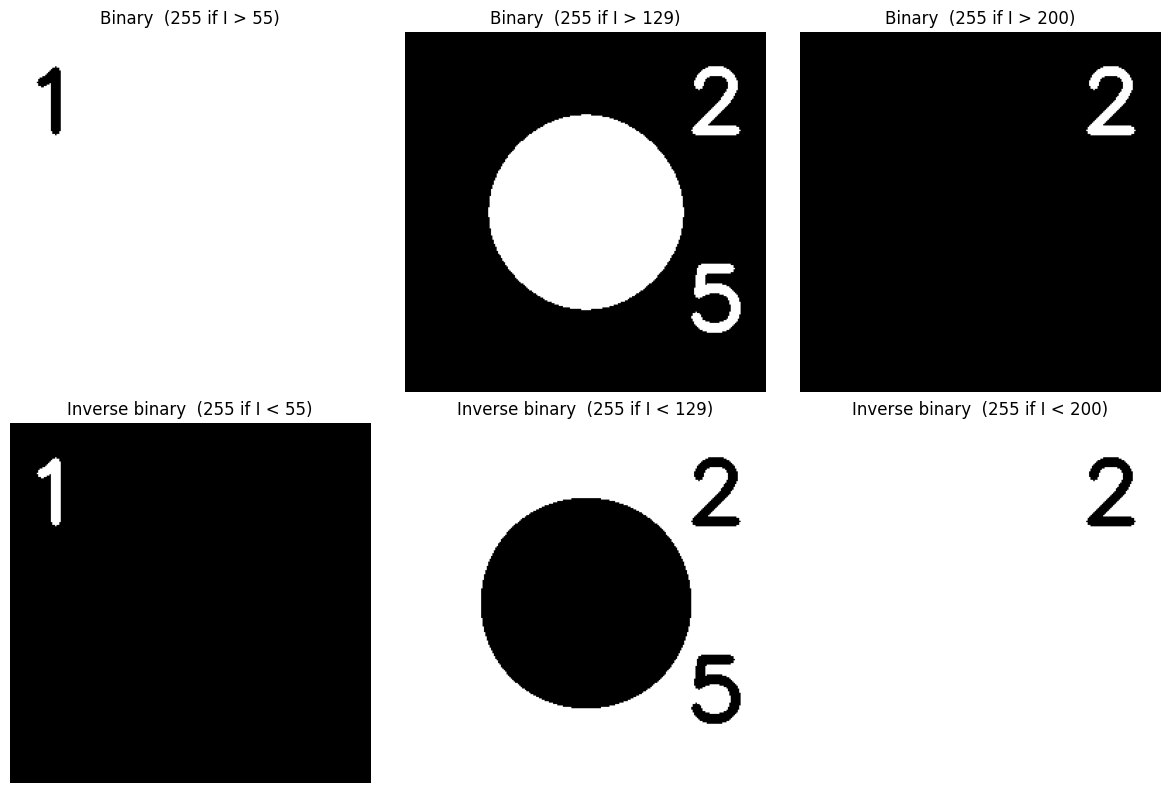

In [5]:
# 6 images: binary and inverse binary at T = 55, 129, 200
fig, ax = plt.subplots(2, 3, figsize=(12, 8))
for j, T in enumerate([55, 129, 200]):
    ax[0, j].imshow(binary(img, T), cmap="gray", vmin=0, vmax=255);     ax[0, j].set_title(f"Binary  (255 if I > {T})")
    ax[1, j].imshow(binary_inv(img, T), cmap="gray", vmin=0, vmax=255); ax[1, j].set_title(f"Inverse binary  (255 if I < {T})")
for a in ax.ravel(): a.axis("off")
plt.tight_layout(); plt.show()

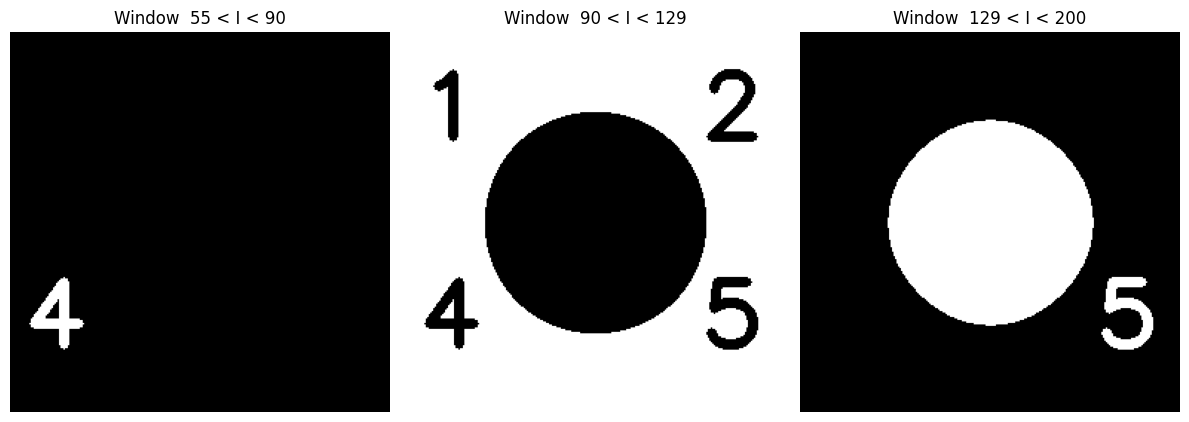

In [6]:
# 3 images: window binary thresholding
fig, ax = plt.subplots(1, 3, figsize=(12, 4.3))
for a, (t1, t2) in zip(ax, [(55, 90), (90, 129), (129, 200)]):
    a.imshow(window(img, t1, t2), cmap="gray", vmin=0, vmax=255); a.set_title(f"Window  {t1} < I < {t2}"); a.axis("off")
plt.tight_layout(); plt.show()

Foreground pixels with 129 < I < 131: 2916
Connected components of the value-130 pixels (area): [2192, 724]
-> digit 3 = 724 px, but a ring of the disc also has value 130 (2192 px)


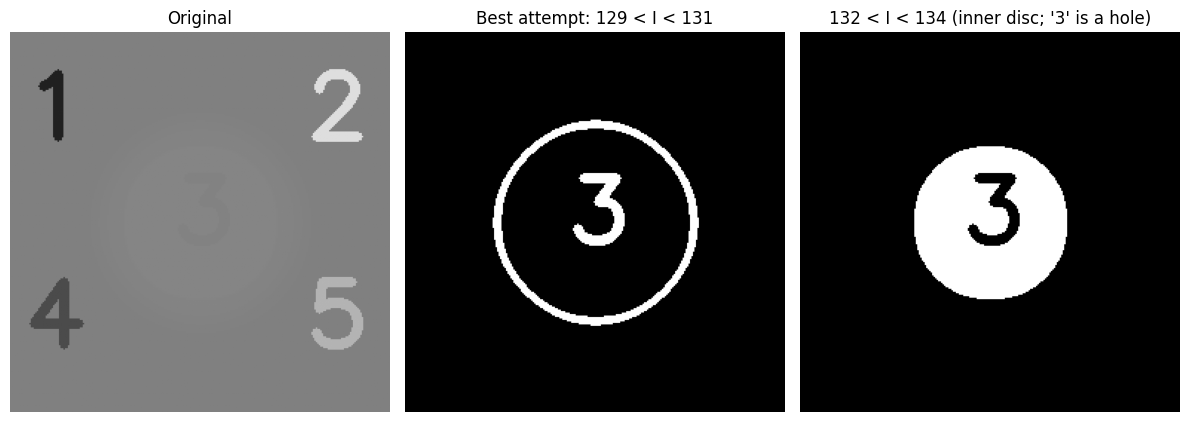

In [7]:
# Can we isolate ONLY digit 3 (intensity 130)?
res = window(img, 129, 131)
print("Foreground pixels with 129 < I < 131:", int((res == 255).sum()))
n, lab, st, _ = cv2.connectedComponentsWithStats((img == 130).astype(np.uint8), connectivity=8)
print("Connected components of the value-130 pixels (area):", [int(st[i, 4]) for i in range(1, n)])
print("-> digit 3 = 724 px, but a ring of the disc also has value 130 (2192 px)")

fig, ax = plt.subplots(1, 3, figsize=(12, 4.3))
ax[0].imshow(img, cmap="gray", vmin=0, vmax=255); ax[0].set_title("Original")
ax[1].imshow(window(img, 129, 131), cmap="gray"); ax[1].set_title("Best attempt: 129 < I < 131")
ax[2].imshow(window(img, 132, 134), cmap="gray"); ax[2].set_title("132 < I < 134 (inner disc; '3' is a hole)")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

# #2 Denoising

Noisy image source: provided noisy.png
PSNR noisy vs clean: 22.31 dB


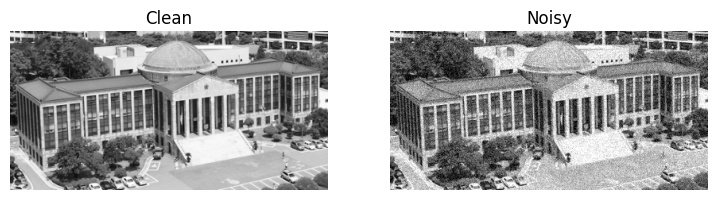

In [8]:
clean = cv2.imread(find("clean.png"), cv2.IMREAD_GRAYSCALE)
try:
    noisy = cv2.imread(find("noisy.png"), cv2.IMREAD_GRAYSCALE); src = "provided noisy.png"
except FileNotFoundError:
    rng = np.random.default_rng(0)
    noisy = np.clip(clean + rng.normal(0, 25, clean.shape), 0, 255).astype(np.uint8)
    src = "SYNTHETIC noise (sigma=25) - upload data/noisy.png and re-run for the real result"
print("Noisy image source:", src)
def psnr(a, b):
    mse = np.mean((a.astype(float) - b.astype(float)) ** 2)
    return 10 * np.log10(255 ** 2 / mse)
print("PSNR noisy vs clean: %.2f dB" % psnr(noisy, clean))
rows = []
fig, ax = plt.subplots(1, 2, figsize=(9, 5))
ax[0].imshow(clean, cmap="gray", vmin=0, vmax=255); ax[0].set_title("Clean")
ax[1].imshow(noisy, cmap="gray", vmin=0, vmax=255); ax[1].set_title("Noisy")
for a in ax: a.axis("off")
plt.show()

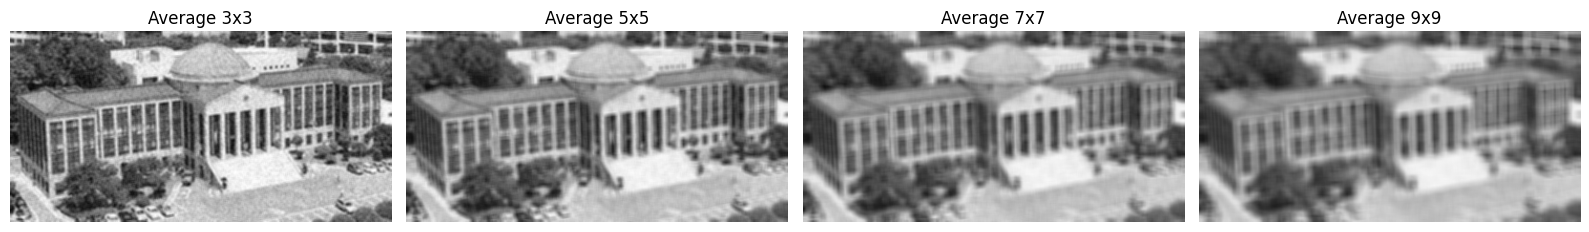

In [21]:
# Average filter
fig, ax = plt.subplots(1, 4, figsize=(16, 4.5))
for a, k in zip(ax, [3, 5, 7, 9]):
    out = cv2.blur(noisy, (k, k)); p = psnr(out, clean); rows.append((f"Average {k}x{k}", p))
    a.imshow(out, cmap="gray", vmin=0, vmax=255); a.set_title(f"Average {k}x{k}"); a.axis("off")
plt.tight_layout(); plt.show()

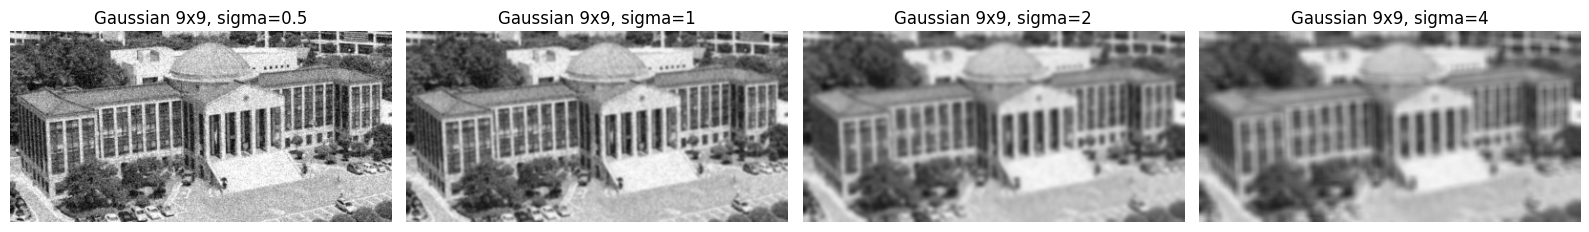

In [22]:
# Gaussian filter
fig, ax = plt.subplots(1, 4, figsize=(16, 4.5))
for a, s in zip(ax, [0.5, 1, 2, 4]):
    out = cv2.GaussianBlur(noisy, (9, 9), sigmaX=s, sigmaY=s); p = psnr(out, clean); rows.append((f"Gaussian 9x9 sigma={s}", p))
    a.imshow(out, cmap="gray", vmin=0, vmax=255); a.set_title(f"Gaussian 9x9, sigma={s}"); a.axis("off")
plt.tight_layout(); plt.show()

In [11]:
# Which of the 8 filters is best? (PSNR vs clean, higher = better)
for name, p in rows: print(f"{name:26s} PSNR = {p:.2f} dB")
best = max(rows, key=lambda r: r[1])
print(f"\nBEST of the 8: {best[0]}  ({best[1]:.2f} dB)   [noisy input was {psnr(noisy, clean):.2f} dB]")

Average 3x3                PSNR = 23.35 dB
Average 5x5                PSNR = 20.15 dB
Average 7x7                PSNR = 18.53 dB
Average 9x9                PSNR = 17.59 dB
Gaussian 9x9 sigma=0.5     PSNR = 25.29 dB
Gaussian 9x9 sigma=1       PSNR = 23.39 dB
Gaussian 9x9 sigma=2       PSNR = 19.72 dB
Gaussian 9x9 sigma=4       PSNR = 18.16 dB

BEST of the 8: Gaussian 9x9 sigma=0.5  (25.29 dB)   [noisy input was 22.31 dB]


# #3 Canny Edge Detection


sigma per K: {3: 0.8, 7: 1.4, 11: 2.0}


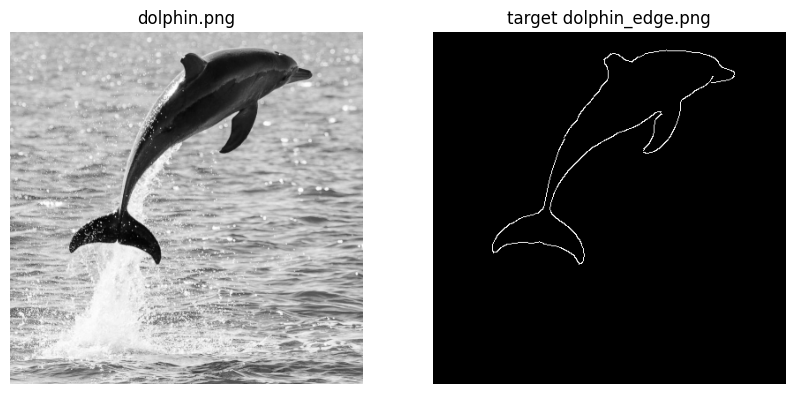

In [12]:
dol = cv2.imread(find("dolphin.png"), cv2.IMREAD_GRAYSCALE)
gt  = cv2.imread(find("dolphin_edge.png"), cv2.IMREAD_GRAYSCALE) > 127

def sigma_of(K): return 0.3 * ((K - 1) * 0.5 - 1) + 0.8
def canny(K, L, H):
    return cv2.Canny(cv2.GaussianBlur(dol, (K, K), 0), L, H) > 0     # sigma=0 -> assignment formula

def prf(pred, gt, tol=2):
    k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (2*tol+1, 2*tol+1))
    gd = cv2.dilate(gt.astype(np.uint8), k) > 0
    pd_ = cv2.dilate(pred.astype(np.uint8), k) > 0
    P = (pred & gd).sum() / max(pred.sum(), 1); R = (gt & pd_).sum() / max(gt.sum(), 1)
    return P, R, 2*P*R / max(P+R, 1e-9)

print("sigma per K:", {K: round(sigma_of(K), 2) for K in (3, 7, 11)})
fig, ax = plt.subplots(1, 2, figsize=(10, 5))
ax[0].imshow(dol, cmap="gray"); ax[0].set_title("dolphin.png"); ax[1].imshow(gt, cmap="gray"); ax[1].set_title("target dolphin_edge.png")
for a in ax: a.axis("off")
plt.show()

K= 3 L= 50 H=100  edge px= 33174  P=0.040 R=1.000 F1=0.077
K= 3 L= 50 H=150  edge px= 28515  P=0.046 R=1.000 F1=0.088
K= 3 L= 50 H=200  edge px= 23802  P=0.055 R=1.000 F1=0.104
K= 3 L=100 H=100  edge px= 23781  P=0.056 R=1.000 F1=0.106
K= 3 L=100 H=150  edge px= 20134  P=0.065 R=1.000 F1=0.123
K= 3 L=100 H=200  edge px= 16108  P=0.081 R=1.000 F1=0.150
K= 3 L=150 H=100  edge px= 20134  P=0.065 R=1.000 F1=0.123
K= 3 L=150 H=150  edge px= 13599  P=0.096 R=1.000 F1=0.176
K= 3 L=150 H=200  edge px= 11292  P=0.116 R=1.000 F1=0.207
K= 7 L= 50 H=100  edge px= 17322  P=0.071 R=1.000 F1=0.132
K= 7 L= 50 H=150  edge px= 10402  P=0.117 R=1.000 F1=0.210
K= 7 L= 50 H=200  edge px=  5216  P=0.234 R=1.000 F1=0.380
K= 7 L=100 H=100  edge px=  9143  P=0.134 R=1.000 F1=0.236
K= 7 L=100 H=150  edge px=  6100  P=0.200 R=1.000 F1=0.334
K= 7 L=100 H=200  edge px=  3277  P=0.373 R=1.000 F1=0.543
K= 7 L=150 H=100  edge px=  6100  P=0.200 R=1.000 F1=0.334
K= 7 L=150 H=150  edge px=  3438  P=0.354 R=1.000 F1=0.5

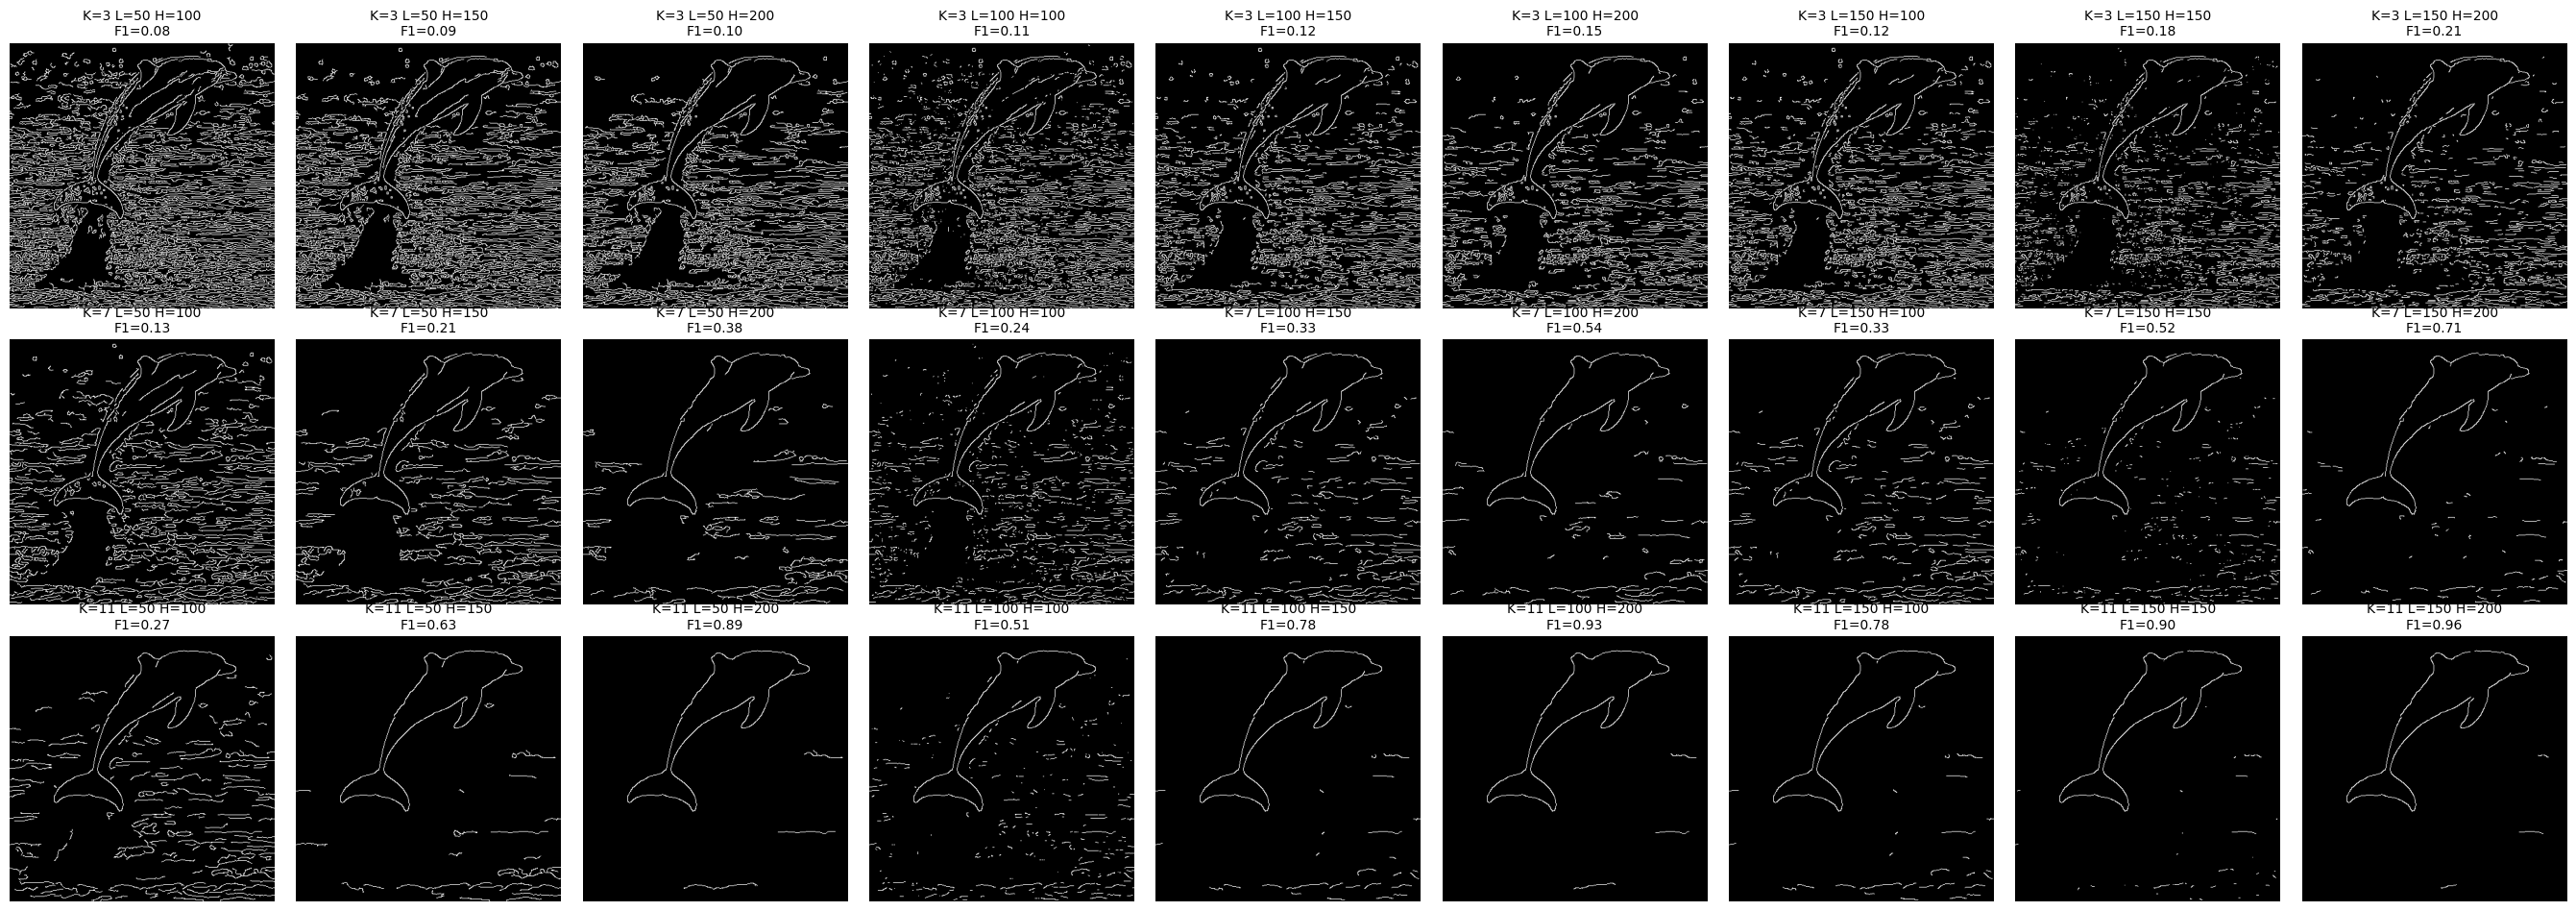

In [13]:
# All 27 (K, L, H) combinations
results = []
for K, L, H in itertools.product([3, 7, 11], [50, 100, 150], [100, 150, 200]):
    e = canny(K, L, H); P, R, F = prf(e, gt); results.append(((K, L, H), e, int(e.sum()), P, R, F))
    print(f"K={K:2d} L={L:3d} H={H:3d}  edge px={int(e.sum()):6d}  P={P:.3f} R={R:.3f} F1={F:.3f}")

fig, ax = plt.subplots(3, 9, figsize=(27, 9.5))
for a, (t, e, n, P, R, F) in zip(ax.ravel(), results):
    a.imshow(e, cmap="gray"); a.set_title(f"K={t[0]} L={t[1]} H={t[2]}\nF1={F:.2f}", fontsize=10); a.axis("off")
plt.tight_layout(); plt.show()

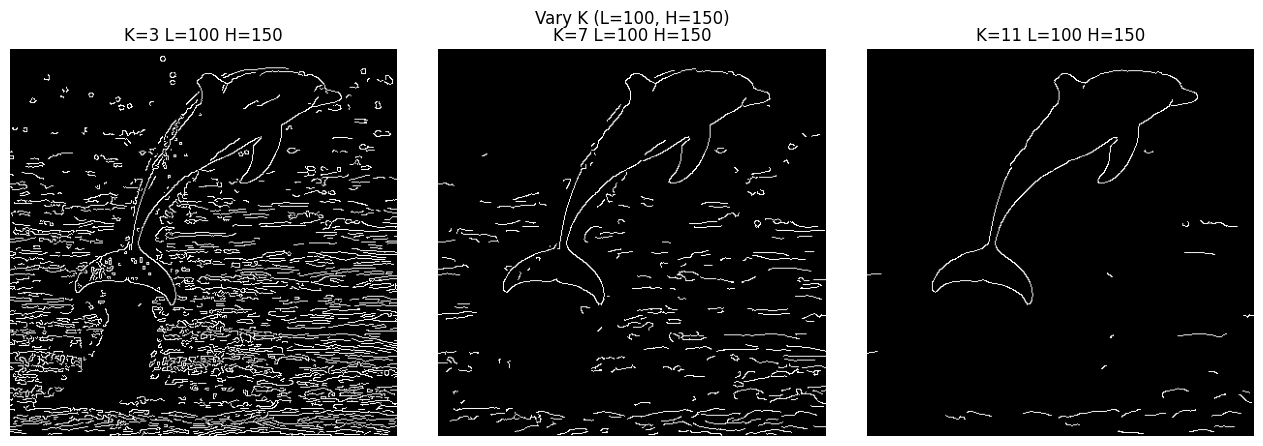

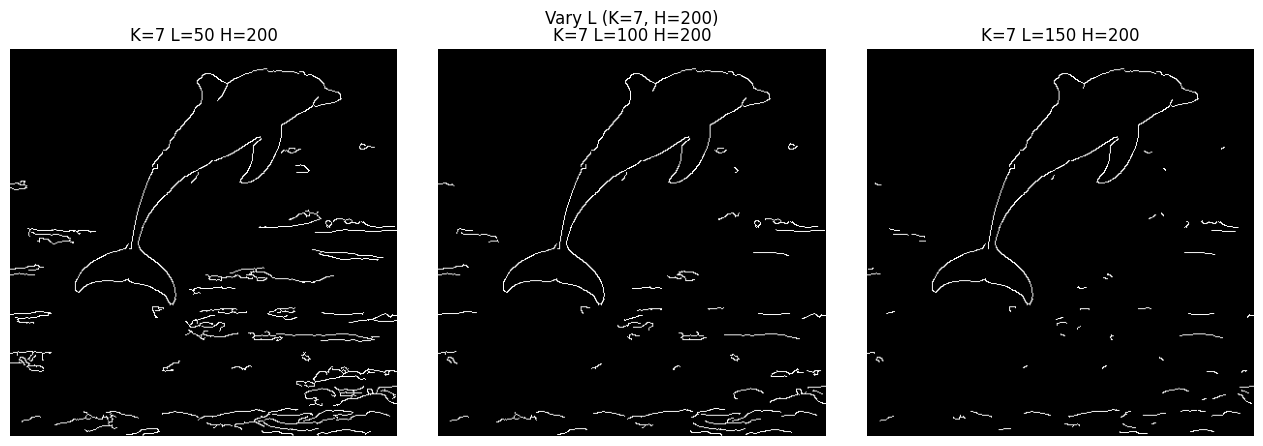

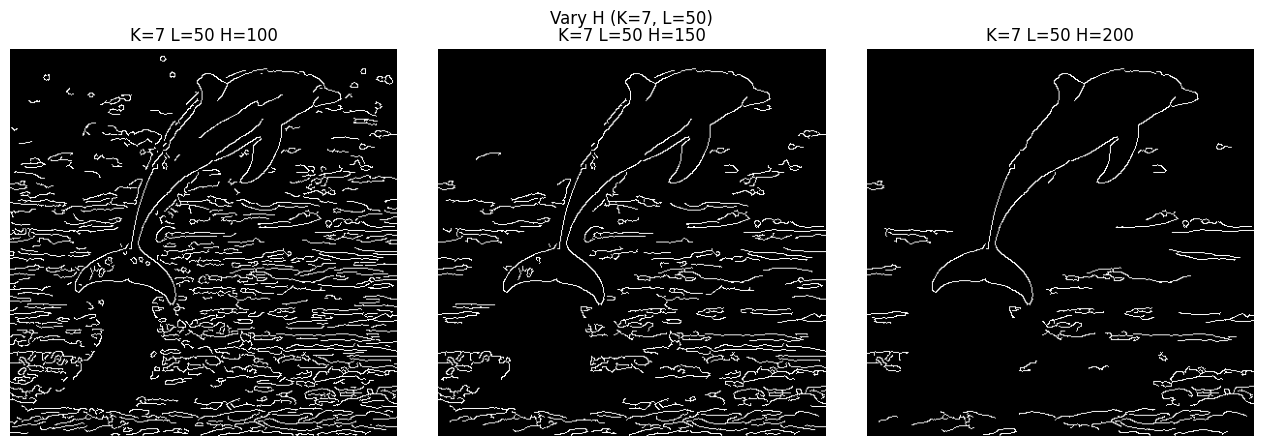

In [14]:
# One hyper-parameter at a time (others held fixed)
def row(title, cfgs):
    fig, ax = plt.subplots(1, 3, figsize=(13, 4.5))
    for a, c in zip(ax, cfgs):
        a.imshow(canny(*c), cmap="gray"); a.set_title(f"K={c[0]} L={c[1]} H={c[2]}"); a.axis("off")
    fig.suptitle(title); plt.tight_layout(); plt.show()
row("Vary K (L=100, H=150)", [(3,100,150), (7,100,150), (11,100,150)])
row("Vary L (K=7, H=200)",   [(7,50,200), (7,100,200), (7,150,200)])
row("Vary H (K=7, L=50)",    [(7,50,100), (7,50,150), (7,50,200)])

Best (K,L,H) = (11, 150, 200)  precision=0.934 recall=0.993 F1=0.963


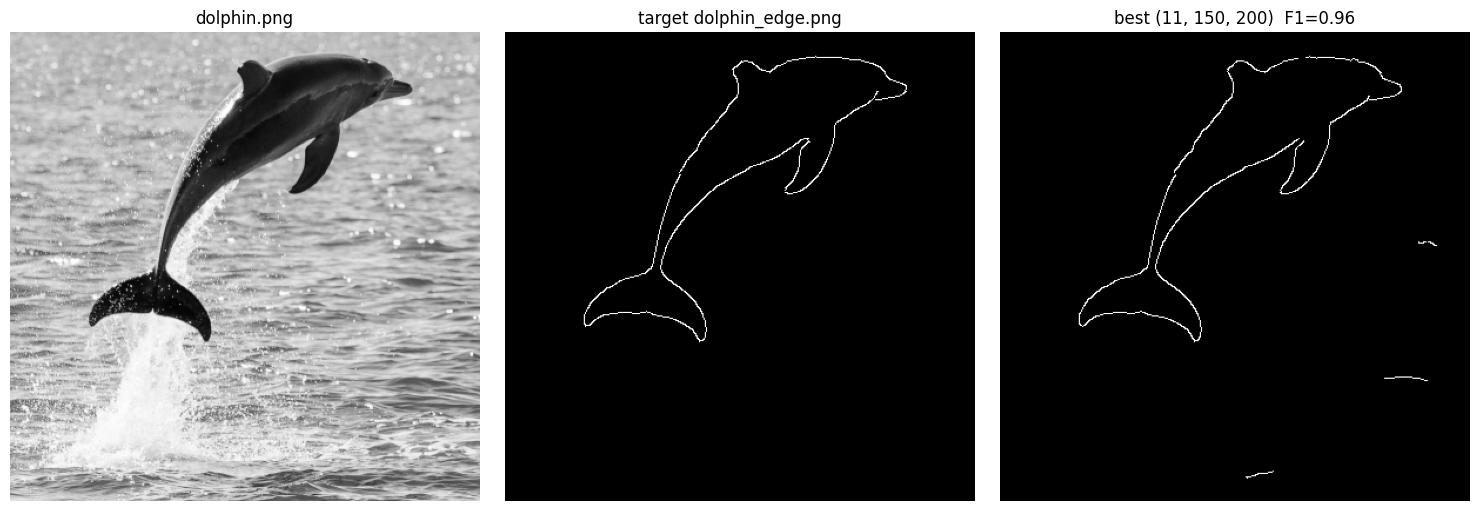

In [15]:
best = max([r for r in results if r[0][1] <= r[0][2]], key=lambda r: r[5])
print("Best (K,L,H) =", best[0], " precision=%.3f recall=%.3f F1=%.3f" % best[3:])
fig, ax = plt.subplots(1, 3, figsize=(15, 5))
ax[0].imshow(dol, cmap="gray"); ax[0].set_title("dolphin.png")
ax[1].imshow(gt, cmap="gray");  ax[1].set_title("target dolphin_edge.png")
ax[2].imshow(best[1], cmap="gray"); ax[2].set_title("best %s  F1=%.2f" % (best[0], best[5]))
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

# #4 Chamfer Distance

In [16]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
import random

def get_binary_image_array(image_path, threshold=0.5):
    """
    Convert an image to a binary NumPy array.

    Args:
        image_path (str): Path to the input image.
        threshold (float): Threshold for binarization (0 to 1 for normalized pixel values).

    Returns:
        numpy.ndarray: Binary image as a NumPy array.
    """
    image = plt.imread(image_path)

    # If the image has an alpha channel (RGBA), ignore it
    if image.shape[-1] == 4:  # Check if it's RGBA
        image = image[:, :, :3]  # Use only RGB channels

    # Convert to grayscale by averaging RGB channels
    grayscale = np.mean(image, axis=2)

    # Convert to binary by applying a threshold
    binary_image = (grayscale > threshold).astype(np.uint8)

    return binary_image


def generate_triangle_edge_template():
    """Generate a binary triangle edge template with diagonal, top row, and right column."""
    h, w = 40, 40  # Height and width of the triangle template
    template = np.zeros((h, w), dtype=np.uint8)  # Start with a black image

    # Set the diagonal pixels
    for i in range(h):
        template[i, i] = 1

    # Set the top row pixels
    template[0, :] = 1

    # Set the right column pixels
    template[:, -1] = 1

    return template

def overlay_template_edges_on_feature(scene, template, match_position):
    """
    Overlay the edges of the template (pixel=1) in red on the feature image.

    Args:
        scene (numpy.ndarray): Binary scene image (grayscale).
        template (numpy.ndarray): Binary template image.
        match_position (tuple): (y, x) position of the best match in the scene.

    Returns:
        numpy.ndarray: RGB feature image with the template edges overlayed in red.
    """
    # Normalize the scene to be in range [0, 255] if necessary
    scene = (scene > 0).astype(np.uint8) * 255  # Ensure binary values are scaled to 255

    # Convert the scene to RGB
    overlay_map = np.stack([scene, scene, scene], axis=-1)  # Grayscale to RGB

    # Extract match position and template dimensions
    y, x = match_position
    th, tw = template.shape

    # Overlay only the edges (pixels with value = 1) of the template in red
    template_edges = (template == 1)  # Binary mask of the edges
    overlay_map[y:y+th, x:x+tw, 0][template_edges] = 255  # Set red channel for edge pixels
    overlay_map[y:y+th, x:x+tw, 1][template_edges] = 0    # Green channel remains 0
    overlay_map[y:y+th, x:x+tw, 2][template_edges] = 0    # Blue channel remains 0

    return overlay_map

## Q4.1 Distance transform (Manhattan, two-pass dynamic programming)


In [17]:
def distance_transform_manhattan(image_features):

    h, w = image_features.shape
    dist_map = np.full((h, w), np.inf)
    dist_map[image_features == 1] = 0
    # Forward pass: look at UP and LEFT neighbours
    for y in range(h):
        for x in range(w):
            if y > 0:
                dist_map[y, x] = min(dist_map[y, x], dist_map[y - 1, x] + 1)
            if x > 0:
                dist_map[y, x] = min(dist_map[y, x], dist_map[y, x - 1] + 1)
    # Backward pass: look at DOWN and RIGHT neighbours
    for y in range(h - 1, -1, -1):
        for x in range(w - 1, -1, -1):
            if y < h - 1:
                dist_map[y, x] = min(dist_map[y, x], dist_map[y + 1, x] + 1)
            if x < w - 1:
                dist_map[y, x] = min(dist_map[y, x], dist_map[y, x + 1] + 1)
    return dist_map

In [18]:
# Q4.1 answer block
image_features = np.array([
    [0, 0, 0, 1],
    [0, 0, 1, 0],
    [0, 1, 0, 0],
    [1, 0, 0, 0]
], dtype=np.uint8)

dist_map_features = distance_transform_manhattan(image_features)
print("Distance Map for Image Features:")
print(dist_map_features)

Distance Map for Image Features:
[[3. 2. 1. 0.]
 [2. 1. 0. 1.]
 [1. 0. 1. 2.]
 [0. 1. 2. 3.]]


## Q4.2 Chamfer matching

In [19]:
# Chamfer distance matching
def chamfer_matching(scene, template):

    scene = (scene > 0).astype(np.uint8)
    dist_transform = distance_transform_manhattan(scene)
    H, W = scene.shape
    th, tw = template.shape
    out_h, out_w = H - th + 1, W - tw + 1

    ty, tx = np.nonzero(template)
    n_edge = len(ty)

    chamfer_map = np.zeros((out_h, out_w), dtype=np.float64)
    for y in range(out_h):
        for x in range(out_w):
            chamfer_map[y, x] = dist_transform[y + ty, x + tx].sum() / n_edge

    best_match_position = np.unravel_index(np.argmin(chamfer_map), chamfer_map.shape)
    best_match_position = (int(best_match_position[0]), int(best_match_position[1]))
    # Normalize Chamfer map
    chamfer_map = (chamfer_map - np.min(chamfer_map)) / (np.max(chamfer_map) - np.min(chamfer_map))

    return best_match_position, chamfer_map

Best match position (y, x): (139, 239)


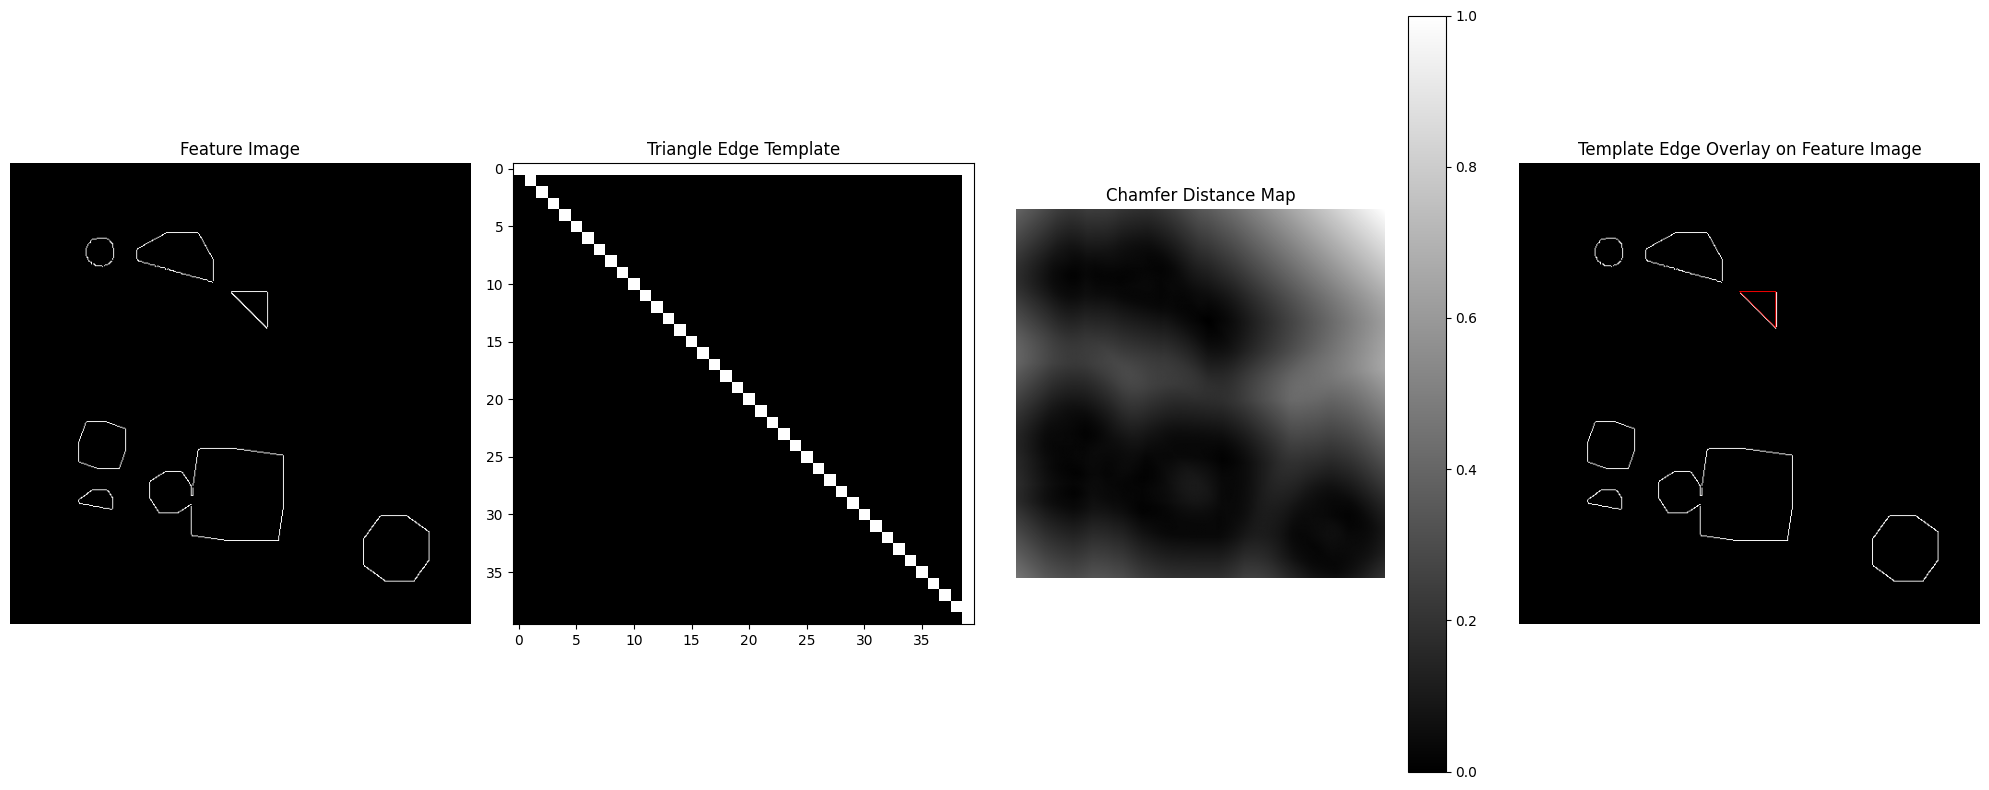

In [20]:
# Q4.2
scene = get_binary_image_array(find("binary_image.png"))
scene = cv2.Canny(scene, 0, 1)
template = generate_triangle_edge_template()
best_match_position, chamfer_map = chamfer_matching(scene, template)
print("Best match position (y, x):", best_match_position)
overlayed_feature_image = overlay_template_edges_on_feature(scene, template, best_match_position)

plt.figure(figsize=(20, 8))
plt.subplot(1, 4, 1); plt.title("Feature Image"); plt.imshow(scene, cmap="gray"); plt.axis("off")
plt.subplot(1, 4, 2); plt.title("Triangle Edge Template"); plt.imshow(template, cmap="gray")
plt.subplot(1, 4, 3); plt.title("Chamfer Distance Map"); plt.imshow(chamfer_map, cmap="gray"); plt.colorbar(); plt.axis("off")
plt.subplot(1, 4, 4); plt.title("Template Edge Overlay on Feature Image"); plt.imshow(overlayed_feature_image); plt.axis("off")
plt.tight_layout(); plt.show()